## Task 1
الداتا قبل الذكاء الاصطناعي
### 1. Garbage In, Garbage Out

تعني أن البيانات الخاطئة تؤدي إلى نتائج خاطئة، حتى لو كان نموذج الذكاء الاصطناعي قويًا.

مثال من مجال الكاشير: بياناتنا هي أسعار المنتجات وكميات المبيعات. لو سُجّل سعر منتج بـ500 ريال بدلًا من 50 ريالًا، فقد يتعلم النموذج أن مبيعات هذا المنتج أعلى من حقيقتها، ويتوقع له إيرادات مرتفعة. وقد يدفع ذلك المتجر إلى زيادة مخزونه بناءً على توقع خاطئ.

### 2. اكتشاف مشكلات البيانات

| المشكلة ومكانها | نوعها | قرار المعالجة | السبب |
|---|---|---|---|
| عمر Reem في الطلب 1003 مفقود NaN | Null | أتحقق من المصدر، وإن تعذر أعوّضه بوسيط الأعمار الصحيحة | للحفاظ على الصف وتقليل تأثير القيم المتطرفة |
| الطلب 1002 للعميلة Noura مكرر بالكامل | Duplicate | أحذف نسخة واحدة | حتى لا يُحسب الطلب مرتين |
| عمر Hind في الطلب 1004 يساوي 250 | Outlier | أراجع المصدر وأصححه، وإن تعذر أعتبره قيمة مفقودة | العمر غير منطقي |
| المدينة مكتوبة Riyadh وriyadh | Inconsistency | أوحّد الكتابة إلى Riyadh | لأنهما المدينة نفسها |
| مبلغ الطلب 1005 مكتوب three hundred | Wrong type | أحوّله إلى الرقم 300 | حتى يمكن إجراء العمليات الحسابية عليه |

### 3. تحديد Target وFeatures

المشكلة: التنبؤ بقيمة مبيعات اليوم في متجر بالرياض.

Target:
إجمالي مبيعات اليوم بالريال، وهو ما نريد أن يتوقعه النموذج.

Features:
1. يوم الأسبوع.
2. عدد ساعات عمل المتجر.
3. وجود عروض أو تخفيضات.
4. مبيعات اليوم السابق.
5. هل اليوم إجازة رسمية؟

العمود الذي لن أدخله للموديل:
رقم السجل؛ لأنه مجرد معرّف، ولا يوضح سبب ارتفاع المبيعات أو انخفاضها.

### 4. لماذا يستغرق تجهيز البيانات وقتًا كبيرًا؟

لأن البيانات قد تحتوي على قيم ناقصة أو مكررة أو أخطاء، ونحتاج إلى فحصها وتصحيحها وتوحيد تنسيقها.
ونختار المعلومات المفيدة للمشكلة حتى يتعلم النموذج من بيانات صحيحة وتكون نتائجه أكثر موثوقية.

## Task 2
بيئة العمل وأول array

In [23]:
import numpy as np
import pandas as pd

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

NumPy version: 2.4.6
Pandas version: 2.2.3


In [24]:
import zipfile

with zipfile.ZipFile("/content/archive (1).zip", "r") as z:
    z.extractall("/content")
    print(z.namelist())

['test_Y3wMUE5_7gLdaTN.csv', 'train_u6lujuX_CVtuZ9i.csv']


### توقعاتي قبل تشغيل الكود
1. أتوقع أن prices_list * 2 يكرر القائمة مرتين:
[25, 18, 32, 25, 18, 32]

2. أتوقع أن prices * 2 يضرب كل عنصر في 2:
[50, 36, 64]

3. أتوقع أن prices_list + [1, 1, 1] يضيف العناصر إلى نهاية القائمة:
[25, 18, 32, 1, 1, 1]

4. أتوقع أن prices + np.array([1, 1, 1]) يزيد كل عنصر بمقدار 1:
[26, 19, 33]

In [25]:
prices_list = [25, 18, 32]
prices = np.array(prices_list)

print(prices_list * 2)
print(prices * 2)
print(prices_list + [1, 1, 1])
print(prices + np.array([1, 1, 1]))

[25, 18, 32, 25, 18, 32]
[50 36 64]
[25, 18, 32, 1, 1, 1]
[26 19 33]


In [26]:
print("shape:", prices.shape)
print("ndim:", prices.ndim)
print("size:", prices.size)
print("dtype:", prices.dtype)

shape: (3,)
ndim: 1
size: 3
dtype: int64


In [27]:
a = np.array([1, 2.5, 3])
b = np.array([1, "2", 3])

print("a:", a)
print("a dtype:", a.dtype)

print("b:", b)
print("b dtype:", b.dtype)

a: [1.  2.5 3. ]
a dtype: float64
b: ['1' '2' '3']
b dtype: <U21


### ملاحظاتي بعد التشغيل

نتائج العمليات الأربع طابقت التوقعات؛ قائمة Python تتكرر عند الضرب وتندمج عند الجمع، بينما مصفوفة NumPy تنفذ الحساب على كل عنصر.

في المصفوفة a تحولت الأعداد الصحيحة إلى أعداد عشرية، وأصبح النوع float64 بسبب وجود 2.5.

في المصفوفة b تحولت العناصر إلى نصوص بسبب وجود "2"، وظهر النوع <U21، وهو نوع نصي.

تستخدم مصفوفة NumPy العادية نوع بيانات موحدًا لعناصرها، مما يساعد على تخزينها بكفاءة وتنفيذ العمليات بسرعة.

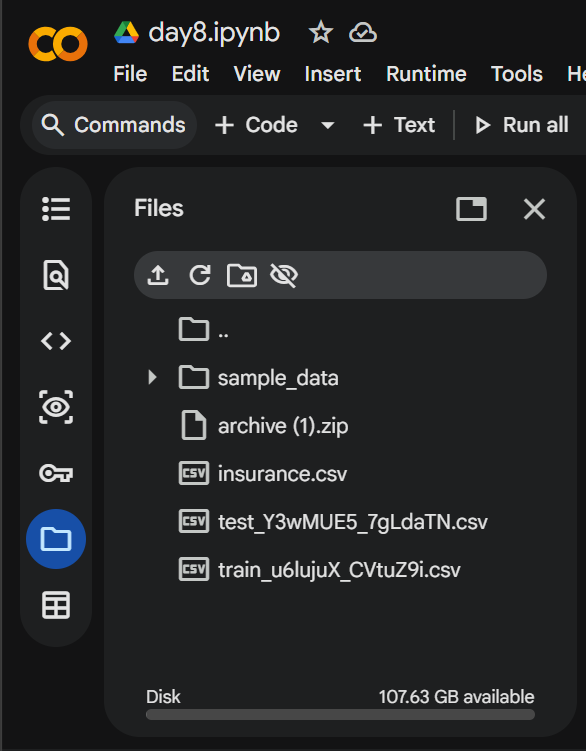

## Task 3
أسبوع كافيه في الرياض

In [28]:
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
sales = np.array([1240, 980, 1105, 1320, 1875, 2410, 2150])

In [29]:
print("Total:", sales.sum())
print("Mean:", sales.mean())
print("Median:", np.median(sales))
print("Maximum:", sales.max())
print("Minimum:", sales.min())
print("Standard deviation:", sales.std())

print("Best day:", days[sales.argmax()], sales.max())
print("Worst day:", days[sales.argmin()], sales.min())

Total: 11080
Mean: 1582.857142857143
Median: 1320.0
Maximum: 2410
Minimum: 980
Standard deviation: 516.8023741020846
Best day: Fri 2410
Worst day: Mon 980


In [30]:
above_average = sales > sales.mean()

print("Above average:", above_average)
print("Days above average:", above_average.sum())
print("Their sales:", sales[above_average])
print("Their days:", np.array(days)[above_average])

Above average: [False False False False  True  True  True]
Days above average: 3
Their sales: [1875 2410 2150]
Their days: ['Thu' 'Fri' 'Sat']


In [31]:
weekend_sales = sales[5:7]
weekend_total = weekend_sales.sum()
weekend_share = weekend_total / sales.sum() * 100

print("Weekend sales:", weekend_sales)
print("Weekend total:", weekend_total)
print("Weekend share:", round(weekend_share, 1), "%")

Weekend sales: [2410 2150]
Weekend total: 4560
Weekend share: 41.2 %


In [32]:
sales_with_tax = sales * 1.15
next_week_target = sales * 1.10

print("Sales with 15% tax:", np.round(sales_with_tax, 2))
print("Next week target:", np.round(next_week_target, 2))
print("Next week total target:", round(next_week_target.sum(), 2))

Sales with 15% tax: [1426.   1127.   1270.75 1518.   2156.25 2771.5  2472.5 ]
Next week target: [1364.  1078.  1215.5 1452.  2062.5 2651.  2365. ]
Next week total target: 12188.0


In [33]:
changes = np.diff(sales)
jump_index = changes.argmax()

print("Daily changes:", changes)
print("Largest increase:", changes[jump_index])
print("From:", days[jump_index])
print("To:", days[jump_index + 1])

Daily changes: [-260  125  215  555  535 -260]
Largest increase: 555
From: Wed
To: Thu


### 7. قراري لصاحب الكافيه

أعطيه الوسيط، وهو 1320 ريالًا، لتمثيل مبيعات يوم عادي؛ لأن مبيعات نهاية الأسبوع المرتفعة رفعت المتوسط إلى نحو 1582.86 ريالًا.
الوسيط أقل تأثرًا بالأيام ذات المبيعات المرتفعة، بينما المتوسط يفيد في معرفة نصيب اليوم من إجمالي مبيعات الأسبوع.

## Task 4
ثلاثة فروع في جدول واحد

In [34]:
branches = ["Riyadh", "Jeddah", "Dammam"]
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]

sales = np.array([
    [1240, 980, 1105, 1320, 1875, 2410, 2150],
    [910, 870, 990, 1010, 1430, 1980, 2240],
    [640, 720, 680, 750, 990, 1210, 1080]
])

print("Shape:", sales.shape)

Shape: (3, 7)


الشكل (3, 7) يعني أن المصفوفة تحتوي على 3 صفوف تمثل الفروع، و7 أعمدة تمثل أيام الأسبوع من الأحد إلى السبت.

In [35]:
print("Jeddah Thursday:", sales[1, 4])
print("Dammam week:", sales[2, :])
print("All branches Friday:", sales[:, 5])
print("All branches weekend:", sales[:, 5:7])

Jeddah Thursday: 1430
Dammam week: [ 640  720  680  750  990 1210 1080]
All branches Friday: [2410 1980 1210]
All branches weekend: [[2410 2150]
 [1980 2240]
 [1210 1080]]


In [36]:
branch_totals = sales.sum(axis=1)
day_totals = sales.sum(axis=0)

print("Branch totals:", branch_totals)
print("Day totals:", day_totals)

Branch totals: [11080  9430  6070]
Day totals: [2790 2570 2775 3080 4295 5600 5470]


axis=1 يجمع أعمدة الأيام داخل كل صف، فيعطيني مجموع مبيعات كل فرع.
axis=0 يجمع صفوف الفروع داخل كل عمود، فيعطيني مجموع مبيعات كل يوم.

In [37]:
best_branch = branch_totals.argmax()
best_day = day_totals.argmax()
branch_shares = branch_totals / sales.sum() * 100

print("Best branch:", branches[best_branch])
print("Best company day:", days[best_day])
print("Branch shares (%):", np.round(branch_shares, 2))

Best branch: Riyadh
Best company day: Fri
Branch shares (%): [41.69 35.48 22.84]


In [38]:
max_index = sales.argmax()
row = max_index // sales.shape[1]
col = max_index % sales.shape[1]

print("Branch:", branches[row])
print("Day:", days[col])
print("Highest sale:", sales[row, col])

Branch: Riyadh
Day: Fri
Highest sale: 2410


### 6. اقتراحي للإدارة

أقترح إغلاق فرع الدمام يوم الأحد؛ لأن مبيعاته في ذلك اليوم هي الأقل بين الفروع: 640 ريالًا، مقابل 910 ريالات لجدة و1240 ريالًا للرياض.
هذا اقتراح بناءً على المبيعات المتاحة، ويحتاج القرار النهائي إلى مقارنة التكاليف والأرباح لكل فرع.

## Task 5
غواصة في أعماق المحيط

In [39]:
depth = np.array([
    120, 340, 610, -1, 890, 1150, 1420, 99999, 1730, 2010,
    2280, -1, 2560, 2840, 99999, 3120, 3390, 3650, -1, 3900
])

invalid = (depth == -1) | (depth == 99999)

print("Invalid count:", invalid.sum())
print("Invalid percentage:", invalid.mean() * 100, "%")

Invalid count: 5
Invalid percentage: 25.0 %


In [40]:
valid_depth = depth[~invalid]

mean_with_errors = depth.mean()
mean_clean = valid_depth.mean()

print("Mean with errors:", mean_with_errors)
print("Mean without errors:", mean_clean)
print("Error factor:", mean_with_errors / mean_clean)

Mean with errors: 11500.25
Mean without errors: 2000.6666666666667
Error factor: 5.748208930356547


In [41]:
print("Median depth (m):", np.median(valid_depth))
print("Maximum depth (m):", valid_depth.max())
print("Maximum depth (ft):", valid_depth.max() * 3.28084)

Median depth (m): 2010.0
Maximum depth (m): 3900
Maximum depth (ft): 12795.276


In [42]:
pressure = valid_depth / 10 + 1

print("Pressure:", pressure)
print("Readings above 300 atm:", (pressure > 300).sum())

Pressure: [ 13.  35.  62.  90. 116. 143. 174. 202. 229. 257. 285. 313. 340. 366.
 391.]
Readings above 300 atm: 4


In [43]:
minutes = np.arange(depth.size)
valid_minutes = minutes[~invalid]

depth_changes = np.diff(valid_depth)
time_changes = np.diff(valid_minutes)
speed = depth_changes / time_changes

print("Descent speed (m/min):", np.round(speed, 2))
print("Approximately constant:", np.allclose(speed, speed.mean(), rtol=0.2))

Descent speed (m/min): [220. 270. 140. 260. 270. 155. 280. 270. 140. 280. 140. 270. 260. 125.]
Approximately constant: False


### 5. ملاحظتي على سرعة النزول
سرعة النزول ليست ثابتة تقريبًا؛ تراوحت بين 125 و280 مترًا في الدقيقة، مع مراعاة الفجوات الزمنية الناتجة عن القراءات الخاطئة.

### 6. معالجة القراءات الخاطئة قبل تدريب النموذج
أستبدل القيمتين -1 و99999 بقيم مفقودة، وأعوّض الفجوات القصيرة بالاستيفاء الخطي بين القراءات السليمة مع الحفاظ على ترتيب الدقائق.
لا أستخدم المتوسط العام للتعويض؛ لأن العمق يتغير مع الزمن. وقد رفعت الأخطاء المتوسط من نحو 2000.67 إلى 11500.25 مترًا، أي حوالي 5.75 أضعاف.
وعند التنبؤ بالمستقبل، أستخدم فقط القراءات المتاحة حتى وقت التنبؤ حتى لا تتسرب معلومات مستقبلية إلى النموذج.